# Buổi F3: Gaussian Mixture, mỗi khách thuộc nhóm nào với xác suất bao nhiêu

**Hiện trường.** Chị Hạnh chia khách bằng K-Means, nhưng có hai chuyện làm chị lấn cấn. Một: nhóm khách của chị không tròn, mà **dẹt và nghiêng** (khách trẻ chi ít, khách lớn tuổi chi nhiều hơn theo một đường chéo). Hai: có những khách nằm giữa hai nhóm, K-Means vẫn ép họ vào một nhóm chắc nịch, trong khi thật ra họ "nửa này nửa kia".

Buổi này dạy **hỗn hợp Gauss** (*Gaussian Mixture Model*, GMM): coi dữ liệu là trộn của nhiều **đám mây hình elip**, mỗi đám có tâm, độ rộng và hướng nghiêng riêng. Với mỗi khách, GMM trả về **xác suất** thuộc từng đám.

**Ẩn dụ:** K-Means giống thầy dùng compa vẽ vòng tròn quanh mỗi cái bàn. GMM giống thầy vẽ vòng **bầu dục nghiêng**, và ai ngồi ở chỗ hai vòng chồng nhau thì được ghi "60% nhóm A, 40% nhóm B" thay vì bắt chọn một.

**Mindset của người làm dữ liệu:** "chắc chắn bao nhiêu" cũng là thông tin. Khách nằm ranh giới đáng được đối xử khác khách nằm giữa nhóm.

**Lưu ý:** dữ liệu dựng có chủ đích (`make_blobs` rồi kéo giãn, xoay); dùng để học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: nhóm dẹt nghiêng, K-Means so với GMM |
| Chặng 1 | Thuật toán EM bằng tay trên một cột |
| Chặng 2 | Xác suất thuộc nhóm: ai nằm ở ranh giới |
| Chặng 3 | Hình dạng elip: bốn kiểu covariance_type |
| Chặng 4 | Chọn số nhóm bằng BIC |
| Chặng 5 | Giới hạn: GMM vẫn giả định đám mây elip |

## Chặng 0: Thấy ngay, nhóm dẹt và nghiêng

**Câu hỏi:** khi nhóm là elip nghiêng, K-Means và GMM chia khác nhau thế nào?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

K-Means ARI: 0.899 | GMM ARI: 0.99


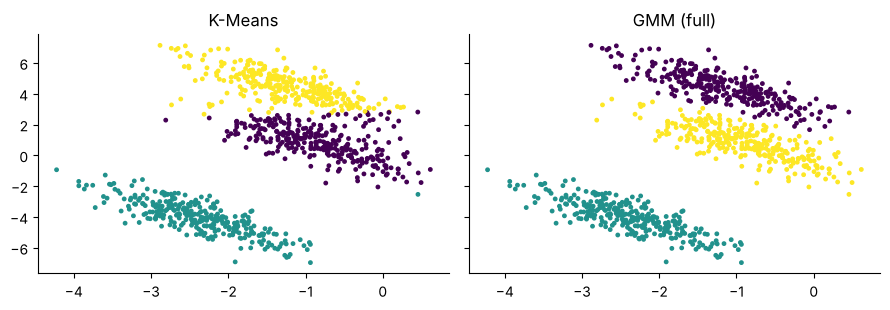

In [2]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score
raw, truth = make_blobs(n_samples=900, centers=3, cluster_std=1.0, random_state=11)
stretch = np.array([[0.6, -0.65], [-0.15, 0.85]])
X = raw @ stretch
lab_km = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X)
gm = GaussianMixture(n_components=3, covariance_type="full", n_init=5, random_state=0).fit(X)
lab_gm = gm.predict(X)
print("K-Means ARI:", round(adjusted_rand_score(truth, lab_km), 3), "| GMM ARI:", round(adjusted_rand_score(truth, lab_gm), 3))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), sharex=True, sharey=True)
ax[0].scatter(*X.T, c=lab_km, s=6); ax[0].set_title("K-Means")
ax[1].scatter(*X.T, c=lab_gm, s=6); ax[1].set_title("GMM (full)")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `raw @ stretch`: nhân với một ma trận để **kéo giãn và xoay** ba đám tròn thành ba đám elip nghiêng. Dữ liệu dựng có chủ đích.
- `GaussianMixture(n_components=3, covariance_type="full", n_init=5)`: hỗn hợp 3 đám Gauss. `full` cho mỗi đám một elip tự do (kích thước và hướng riêng). `n_init=5` thử 5 lần khởi tạo, giữ lần tốt nhất.
- `gm.predict(X)`: gán mỗi điểm vào đám có xác suất cao nhất.

**Cách đọc.**
- **Con số:** K-Means khớp nhóm thật ở mức **0,899**, GMM **0,990**.
- **Bức tranh:** K-Means cắt theo khoảng cách thẳng đến tâm nên cắt ngang đám elip; GMM nhận ra hướng nghiêng của từng đám.
- **Câu hỏi tiếp:** GMM tìm các elip đó bằng cách nào? Ta tự làm trên một cột.

**Mang về chặng 1:** GMM = nhiều đám mây elip trộn lại; mỗi đám có tâm, độ rộng, hướng.

## Chặng 1: Thuật toán EM bằng tay

**Câu hỏi:** không biết khách nào thuộc đám nào, làm sao ước lượng được tâm và độ rộng từng đám?

In [3]:
from scipy.stats import norm
rng = np.random.RandomState(0)
spend = np.concatenate([rng.normal(8, 2, 300), rng.normal(20, 4, 200)])
mu = np.array([5.0, 25.0]); sd = np.array([3.0, 3.0]); w = np.array([0.5, 0.5])
for step in range(1, 51):
    dens = np.stack([w[j] * norm.pdf(spend, mu[j], sd[j]) for j in range(2)], axis=1)
    resp = dens / dens.sum(axis=1, keepdims=True)
    n_j = resp.sum(axis=0)
    w = n_j / len(spend)
    mu_new = (resp * spend[:, None]).sum(axis=0) / n_j
    sd = np.sqrt((resp * (spend[:, None] - mu_new) ** 2).sum(axis=0) / n_j)
    if np.abs(mu_new - mu).max() < 1e-6:
        mu = mu_new
        break
    mu = mu_new
gm1 = GaussianMixture(n_components=2, random_state=0, n_init=5).fit(spend.reshape(-1, 1))
order = np.argsort(gm1.means_.ravel())
print("mine   : means", mu.round(2), "| sd", sd.round(2), "| weights", w.round(3), "| steps", step)
print("sklearn: means", gm1.means_.ravel()[order].round(2), "| sd", np.sqrt(gm1.covariances_.ravel()[order]).round(2), "| weights", gm1.weights_[order].round(3))

mine   : means [ 8.08 19.7 ] | sd [2.02 3.84] | weights [0.606 0.394] | steps 39
sklearn: means [ 8.12 19.84] | sd [2.05 3.72] | weights [0.612 0.388]


**Giải thích từng dòng**

- `rng.normal(8, 2, 300) ... rng.normal(20, 4, 200)`: chi tiêu của 500 khách: 300 người quanh 8 triệu, 200 người quanh 20 triệu. Ta biết đáp án, máy thì không.
- `mu = [5, 25]; sd = [3, 3]; w = [0.5, 0.5]`: đoán khởi đầu: hai tâm, hai độ rộng, hai tỷ lệ. Đoán lệch cũng được.
- `dens / dens.sum(axis=1, keepdims=True)`: **bước E** (*expectation*): với mỗi khách, tính xác suất thuộc từng đám theo đoán hiện tại. Gọi là "trách nhiệm" (`resp`).
- `(resp * spend[:, None]).sum(axis=0) / n_j`: **bước M** (*maximization*): tính lại tâm mỗi đám là trung bình **có trọng số** theo xác suất. Tương tự độ rộng và tỷ lệ.
- `np.abs(mu_new - mu).max() < 1e-6`: lặp E rồi M cho đến khi tâm gần như không dịch.

**Cách đọc.**
- **Con số:** bản tự viết dừng sau **39** vòng, hai tâm **8,08, 19,70**; sklearn cho **8,12, 19,84**. Giá trị thật là 8 và 20.
- **Bức tranh:** K-Means là phiên bản "cứng" của cùng ý này: mỗi khách thuộc trọn một nhóm. GMM giữ lại phần xác suất.
- **Câu hỏi tiếp:** xác suất đó dùng được vào việc gì? Chặng 2.

**Mang về chặng 2:** EM lặp hai bước: ước lượng xác suất thuộc đám, rồi cập nhật đám theo xác suất.

## Chặng 2: Xác suất thuộc nhóm

**Câu hỏi:** những khách nào "nửa này nửa kia"?

customers with top probability < 0.95: 23 of 900 ( 2.6 % )
wrong labels overall: 3 | wrong among unsure: 1 | wrong among sure: 2


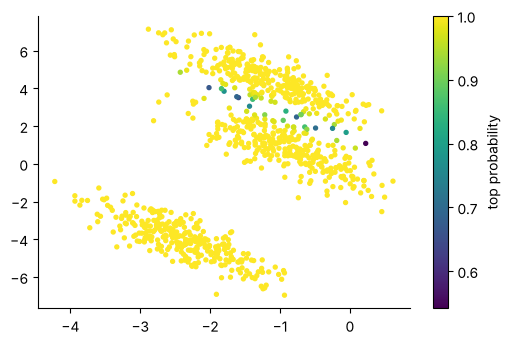

In [4]:
from scipy.optimize import linear_sum_assignment
proba = gm.predict_proba(X)
conf = proba.max(axis=1)
table = pd.crosstab(truth, lab_gm).to_numpy()
r, c = linear_sum_assignment(-table)
mapped = np.empty_like(lab_gm); mapped[:] = -1
for i, j in zip(r, c):
    mapped[lab_gm == j] = i
wrong = mapped != truth
unsure = conf < 0.95
print("customers with top probability < 0.95:", int(unsure.sum()), "of", len(X), "(", round(unsure.mean() * 100, 1), "% )")
print("wrong labels overall:", int(wrong.sum()), "| wrong among unsure:", int(wrong[unsure].sum()), "| wrong among sure:", int(wrong[~unsure].sum()))
fig, ax = plt.subplots(figsize=(6, 3.8))
sc = ax.scatter(*X.T, c=conf, cmap="viridis", s=8); plt.colorbar(sc, label="top probability")
plt.show()

**Giải thích từng dòng**

- `gm.predict_proba(X)`: bảng 900 x 3: xác suất của mỗi khách thuộc mỗi đám; mỗi hàng cộng bằng 1.
- `proba.max(axis=1)`: xác suất cao nhất của khách: càng gần 1 càng chắc nhóm.
- `linear_sum_assignment(-table)`: ghép số nhóm của GMM với số nhóm thật (số 0, 1, 2 của máy là tên tùy ý) để đếm được số khách bị chia sai.
- `conf < 0.95`: gọi khách "chưa chắc" nếu xác suất cao nhất dưới 0,95 (ngưỡng tự chọn).
- `c=conf`: tô màu theo độ chắc: vùng sáng giữa các đám là nơi hai đám chồng nhau.

**Cách đọc.**
- **Con số:** **23** khách (2,6%) có xác suất cao nhất dưới 0,95. Tổng số khách chia sai là **3**, trong đó **1** nằm trong nhóm chưa chắc.
- **Bức tranh:** khách chưa chắc nằm ở vùng chồng nhau giữa hai đám, chiếm tỷ lệ nhỏ nhưng chứa một phần số khách bị chia sai. Biết trước điều đó là lợi thế: gửi ưu đãi chung cho nhóm "ranh giới", hoặc để nhân viên xem tay.
- **Quy tắc đọc:** nhãn cứng cho cái nhìn tổng thể, xác suất cho những quyết định có giá. K-Means không có thông tin này.
- **Câu hỏi tiếp:** "elip tự do" là một lựa chọn. Còn các lựa chọn hình dạng khác?

**Mang về chặng 3:** `predict_proba` cho độ chắc từng khách; dưới ngưỡng thì xử lý riêng.

## Chặng 3: Bốn kiểu hình elip

**Câu hỏi:** cho mỗi đám elip tự do có tốn kém gì không?

In [5]:
rows = []
for ct in ["spherical", "diag", "tied", "full"]:
    m = GaussianMixture(n_components=3, covariance_type=ct, n_init=5, random_state=0).fit(X)
    rows.append({"covariance_type": ct, "ARI": round(adjusted_rand_score(truth, m.predict(X)), 3), "BIC": round(m.bic(X), 1)})
cov_table = pd.DataFrame(rows).set_index("covariance_type")
print(cov_table.to_string())

                   ARI     BIC
covariance_type               
spherical        0.892  6544.3
diag             0.828  6271.3
tied             0.987  5570.9
full             0.990  5606.9


**Giải thích từng dòng**

- `"spherical"`: mỗi đám là hình **tròn** (một độ rộng cho mỗi đám). Gần với K-Means.
- `"diag"`: elip **không nghiêng** (hai độ rộng cho mỗi đám, theo hai trục).
- `"tied"`: mọi đám **dùng chung** một elip nghiêng; chỉ tâm khác nhau.
- `"full"`: mỗi đám một elip nghiêng riêng. Nhiều tham số nhất.
- `m.bic(X)`: điểm BIC: độ khớp trừ đi một khoản phạt vì số tham số. **Càng nhỏ càng tốt.**

**Cách đọc.**
- **Con số:** BIC nhỏ nhất ở **tied** (5570,9); ARI cao nhất ở **full** (0,990). Kiểu `spherical` chỉ đạt ARI **0,892**, `diag` **0,828**.
- **Bức tranh:** `spherical` và `diag` không biểu diễn được độ nghiêng nên kém hẳn. `full` và `tied` đều bắt được độ nghiêng; ở đây `tied` thắng về BIC vì ba đám được kéo cùng một phép biến đổi nên **thật sự chung một elip**, và `tied` đỡ tốn tham số. BIC cân độ khớp với số tham số. Dữ liệu ít mà dùng `full` có thể học thừa (nhớ nhiễu thay vì hình dạng thật).
- **Quy tắc đọc:** khởi đầu với `full` khi có vài trăm điểm trở lên; ít dữ liệu hoặc nhiều cột thì thử `tied` hoặc `diag`; chọn bằng BIC.

**Mang về chặng 4:** BIC là thước đo để chọn cả hình dạng lẫn số nhóm.

## Chặng 4: Chọn số nhóm bằng BIC

**Câu hỏi:** không biết có mấy nhóm, GMM giúp chọn thế nào?

      BIC     AIC
k                
1  7120.0  7096.0
2  5896.1  5843.3
3  5606.9  5525.3
4  5646.0  5535.5
5  5684.5  5545.2
6  5724.1  5556.0
7  5761.1  5564.2


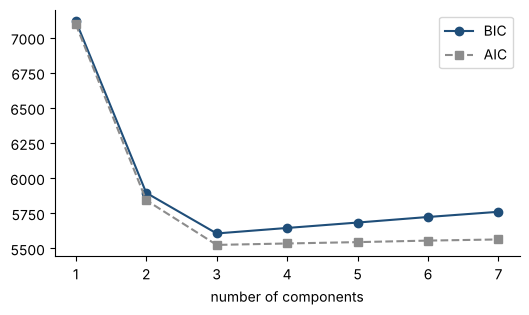

In [6]:
bic_rows = []
for k in range(1, 8):
    m = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=0).fit(X)
    bic_rows.append({"k": k, "BIC": round(m.bic(X), 1), "AIC": round(m.aic(X), 1)})
bic_table = pd.DataFrame(bic_rows).set_index("k")
print(bic_table.to_string())
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(bic_table.index, bic_table["BIC"], "o-", color=BLUE, label="BIC"); ax.plot(bic_table.index, bic_table["AIC"], "s--", color=GRAY, label="AIC")
ax.set_xlabel("number of components"); ax.legend(); plt.show()

**Giải thích từng dòng**

- `for k in range(1, 8)`: thử từ 1 đến 7 đám.
- `m.bic(X) / m.aic(X)`: hai thước chọn mô hình: BIC phạt nặng hơn AIC theo số tham số nên thường chọn ít đám hơn.

**Cách đọc.**
- **Con số:** BIC nhỏ nhất ở **k = 3**, AIC nhỏ nhất ở **k = 3**. Số đám thật là 3.
- **Bức tranh:** từ k = 1 lên 3, BIC giảm mạnh (thêm đám là thêm thông tin thật); từ k = 4 trở đi BIC tăng lại (thêm đám chỉ để ôm nhiễu, bị phạt).
- **Quy tắc đọc:** khác với K-Means, GMM có một thước đo có cơ sở xác suất để chọn `k`. Dùng nó cùng với việc nhóm có dùng được không (F1, chặng 2).

**Mang về chặng 5:** BIC chọn k; hai thước lệch nhau thì chọn theo mục đích.

## Chặng 5: Giới hạn, vẫn là đám mây elip

**Câu hỏi:** GMM có gom được hai hình trăng lồng nhau không?

In [7]:
from sklearn.datasets import make_moons
M, m_truth = make_moons(500, noise=0.07, random_state=0)
gm_moon = GaussianMixture(n_components=2, covariance_type="full", n_init=5, random_state=0).fit(M)
print("moons, GMM ARI:", round(adjusted_rand_score(m_truth, gm_moon.predict(M)), 3))
more = {k: round(GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=0).fit(M).bic(M), 1) for k in range(1, 9)}
print("BIC by k on moons:", more)

moons, GMM ARI: 0.489


BIC by k on moons: {1: 1909.9, 2: 1776.0, 3: 1469.8, 4: 1257.4, 5: 1224.9, 6: 1008.5, 7: 972.9, 8: 952.9}


**Giải thích từng dòng**

- `make_moons(500, noise=0.07)`: hai hình trăng lồng nhau (F2).
- `GaussianMixture(n_components=2, ...)`: ép 2 đám elip.
- `more = {k: ...}`: BIC theo k: xem nó chọn mấy đám.

**Cách đọc.**
- **Con số:** ARI chỉ **0,489**; BIC thấp nhất ở **k = 8** (số nhóm thật là 2); đường BIC còn đang đi xuống ở cuối dải k = 8.
- **Bức tranh:** hình trăng cong không phải elip, nên GMM phải ghép nhiều elip nhỏ để xấp xỉ, và BIC vui vẻ chọn nhiều đám. Con số "k theo BIC" chỉ đúng khi dữ liệu thật sự gần elip.
- **Quy tắc đọc:** GMM hợp khi nhóm là đám mây elip chồng lên nhau và bạn cần xác suất. Nhóm cong thì quay lại DBSCAN (F2).

**Mang về:** chọn thuật toán theo hình dạng nhóm; GMM thêm hai thứ so với K-Means: elip nghiêng và xác suất.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | GMM = trộn nhiều đám mây elip; hợp khi nhóm dẹt, nghiêng. |
| 1 | EM lặp hai bước: tính xác suất thuộc đám, cập nhật đám theo xác suất. |
| 2 | predict_proba cho độ chắc từng khách; khách ranh giới đáng xử lý riêng. |
| 3 | covariance_type chọn mức tự do của elip; BIC cân độ khớp với số tham số. |
| 4 | Chọn số nhóm bằng BIC, kết hợp mục đích dùng. |
| 5 | Nhóm cong thì GMM không hợp; dùng DBSCAN. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Vòng bầu dục nghiêng quanh mỗi bàn | đám Gauss | `GaussianMixture` |
| 60% nhóm A, 40% nhóm B | xác suất thuộc nhóm | `predict_proba` |
| Đoán rồi sửa lại nhiều lần | thuật toán EM | bước E, bước M |
| Độ nghiêng và độ rộng của elip | ma trận hiệp phương sai | `covariance_type` |
| Phạt vì phức tạp thừa | tiêu chí thông tin Bayes | `bic` |
| Tỷ lệ mỗi nhóm trong cả đám đông | trọng số thành phần | `weights_` |

**Thử thách tự làm**

1. Ở chặng 2, đổi ngưỡng 0,95 thành 0,8. Bao nhiêu khách thành chưa chắc? Dùng ngưỡng nào cho chiến dịch ưu đãi và vì sao?
2. Chạy chặng 3 và 4 với chỉ 60 điểm đầu của `X`. BIC còn chọn đúng 3 đám không? Kiểu covariance nào thắng?
3. Ở chặng 1, đổi tâm khởi đầu thành [10, 12]. EM có về lại giá trị đúng không? Thử vài cặp khởi đầu.
4. Dùng `gm.sample(100)` để sinh 100 khách mới từ mô hình. Vẽ chúng lên cùng hình với dữ liệu thật.

**Checklist năng lực** (tự tick khi làm được)

- [ ] Nói được GMM khác K-Means ở hai điểm.
- [ ] Mô tả hai bước của EM.
- [ ] Dùng predict_proba để tách khách chắc và chưa chắc.
- [ ] Chọn k và covariance_type bằng BIC.
- [ ] Biết GMM không hợp nhóm cong.

## Phần thưởng (Tip pro): GMM để phát hiện điểm bất thường


`gm.score_samples(X)` cho **log mật độ** của từng điểm theo mô hình. Điểm có mật độ rất thấp là điểm mà mô hình thấy "lạ". Buổi F6 dùng ý này (và các cách khác) để tìm điểm bất thường.